# 02 · Classifier and baseline comparison (synopsis §4.4, §4.6)

Re-trains both models with repeated stratified cross-validation, then compares the out-of-fold classifier against every resume–JD similarity signal on the same students.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 3)

# Use the real processed dataset when it exists, otherwise the synthetic demo.
REAL = ROOT / "placeiq-data/processed/historical.csv"
DATA = REAL if REAL.exists() else ROOT / "placeiq-data/synthetic/historical.csv"
SYNTHETIC = DATA != REAL
print("Data:", DATA.relative_to(ROOT), "(SYNTHETIC - do not report)" if SYNTHETIC else "(real)")

Data: placeiq-data\synthetic\historical.csv (SYNTHETIC - do not report)


In [2]:
from placeiq.model.train import train
df = pd.read_csv(DATA)
m = train(df, source=str(DATA.relative_to(ROOT)))
rows = {name: {"ROC-AUC (CV mean)": r["roc_auc_mean"], "± sd": r["roc_auc_sd"], "OOF AUC": r["oof_roc_auc"],
               "95% CI low": r["oof_roc_auc_95ci"][0], "95% CI high": r["oof_roc_auc_95ci"][1],
               "accuracy": r["accuracy"], "majority-class accuracy": r["majority_class_accuracy"]}
        for name, r in m["models"].items()}
print(f"n = {m['n_records']}, positive rate = {m['positive_rate']}, indicative only = {m['indicative_only']}")
pd.DataFrame(rows).T

n = 300, positive rate = 0.6233, indicative only = False


,ROC-AUC (CV mean),± sd,OOF AUC,95% CI low,95% CI high,accuracy,majority-class accuracy
logistic_regression,0.757,0.058,0.779,0.723,0.831,0.72,0.623
random_forest,0.790,0.055,0.797,0.742,0.849,0.77,0.623


In [3]:
pd.DataFrame({k: v["classification_report"]["placed"] | {"class": "placed"} for k, v in m["models"].items()}).T

,precision,recall,f1-score,support,class
logistic_regression,0.778,0.77,0.774,187.0,placed
random_forest,0.795,0.85,0.822,187.0,placed


In [4]:
print("Random forest minus logistic regression:", m["random_forest_vs_logistic"])
pd.DataFrame(m["coefficients"]).head(12)

Random forest minus logistic regression: {'auc_diff': 0.0188, 'ci95': [-0.0111, 0.0482], 'p_not_better': 0.1175}


,feature,coefficient
0,cgpa,0.973
1,active_backlogs,-0.865
2,internships,0.608
3,branch_CSE,0.452
4,skills_databases,0.406
5,branch_ECE,-0.339
6,projects,0.257
7,skills_programming,-0.218
8,branch_EEE,-0.215
9,skills_web_frontend,-0.196


## Baseline comparison

Hypothesis: similarity correlates weakly with placement; the outcome-trained classifier correlates substantially more strongly.

In [5]:
bc = m.get("baseline_comparison", {})
if "signals" in bc:
    sig = pd.DataFrame(bc["signals"]).T
    diff = pd.DataFrame(bc["classifier_vs_similarity"]).T
    display(sig.sort_values("roc_auc", ascending=False))
    display(diff)
else:
    print(bc or "No sim_* columns in the data")

,roc_auc,point_biserial_r,p_value
oof_logistic_regression,0.779,0.480,0.000
sim_hybrid,0.545,0.076,0.191
sim_tfidf,0.544,0.070,0.228
sim_sbert,0.540,0.066,0.253
sim_llm_fit,0.504,-0.005,0.936
sim_skill_overlap,0.464,-0.082,0.156


,auc_diff,ci95,p_not_better
sim_hybrid,0.234,"[0.1497, 0.3163]",0.0
sim_llm_fit,0.275,"[0.1834, 0.3648]",0.0
sim_sbert,0.239,"[0.1525, 0.3201]",0.0
sim_skill_overlap,0.314,"[0.2202, 0.3988]",0.0
sim_tfidf,0.234,"[0.1492, 0.3174]",0.0


## Fairness audit

Out-of-fold performance by branch, gender (audit-only) and batch. Gaps above 0.10 are flagged for discussion.

In [6]:
fa = m["fairness"]["attributes"]
for attr, a in fa.items():
    print(f"{attr}: AUC gap {a['auc_gap']}, TPR gap {a['tpr_gap']}, FPR gap {a['fpr_gap']}, calibration gap {a['calibration_gap']}, flags {a['flags']}")
    display(pd.DataFrame(a["groups"]).set_index("group"))

branch: AUC gap 0.2258, TPR gap 0.2065, FPR gap 0.2179, calibration gap 0.0834, flags ['auc_gap', 'tpr_gap', 'fpr_gap']


,n,placement_rate,mean_predicted,auc,tpr,fpr,too_small
group,,,,,,,
CSE,111,0.649,0.565,0.844,0.819,0.282,False
ECE,58,0.534,0.454,0.736,0.613,0.370,False
EEE,31,0.645,0.574,0.618,0.700,0.455,False
IT,74,0.649,0.584,0.781,0.812,0.385,False
ME,26,0.615,0.548,0.762,0.812,0.500,False


gender: AUC gap 0.0064, TPR gap 0.0068, FPR gap 0.0491, calibration gap 0.0786, flags []


,n,placement_rate,mean_predicted,auc,tpr,fpr,too_small
group,,,,,,,
F,109,0.587,0.517,0.783,0.766,0.333,False
M,191,0.644,0.565,0.777,0.772,0.382,False


batch_year: AUC gap 0.1463, TPR gap 0.13, FPR gap 0.1274, calibration gap 0.0812, flags ['auc_gap', 'tpr_gap', 'fpr_gap']


,n,placement_rate,mean_predicted,auc,tpr,fpr,too_small
group,,,,,,,
2024,150,0.640,0.559,0.857,0.833,0.296,False
2025,150,0.607,0.537,0.711,0.703,0.424,False


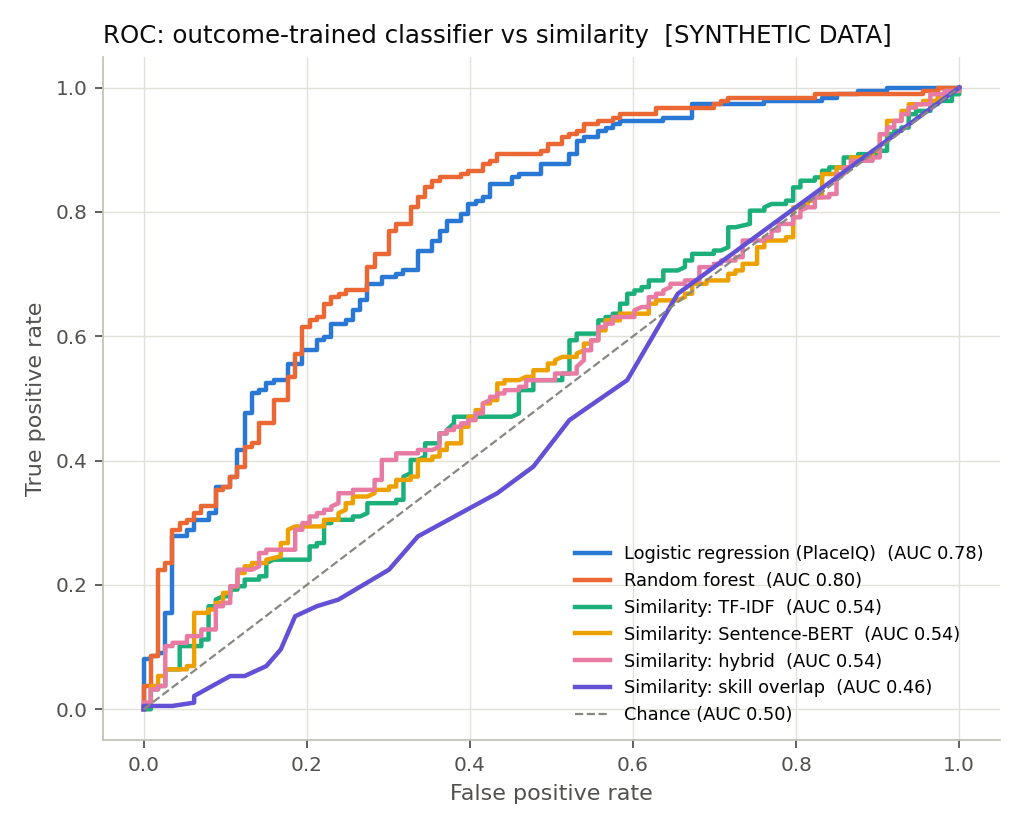

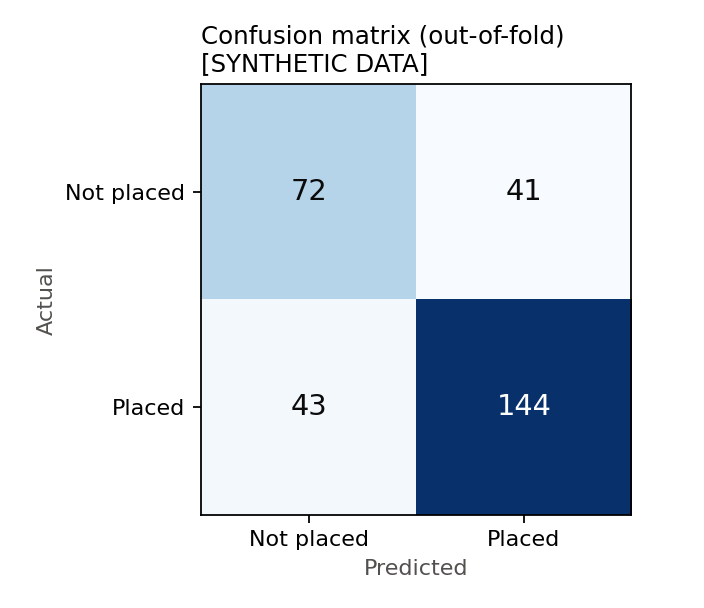

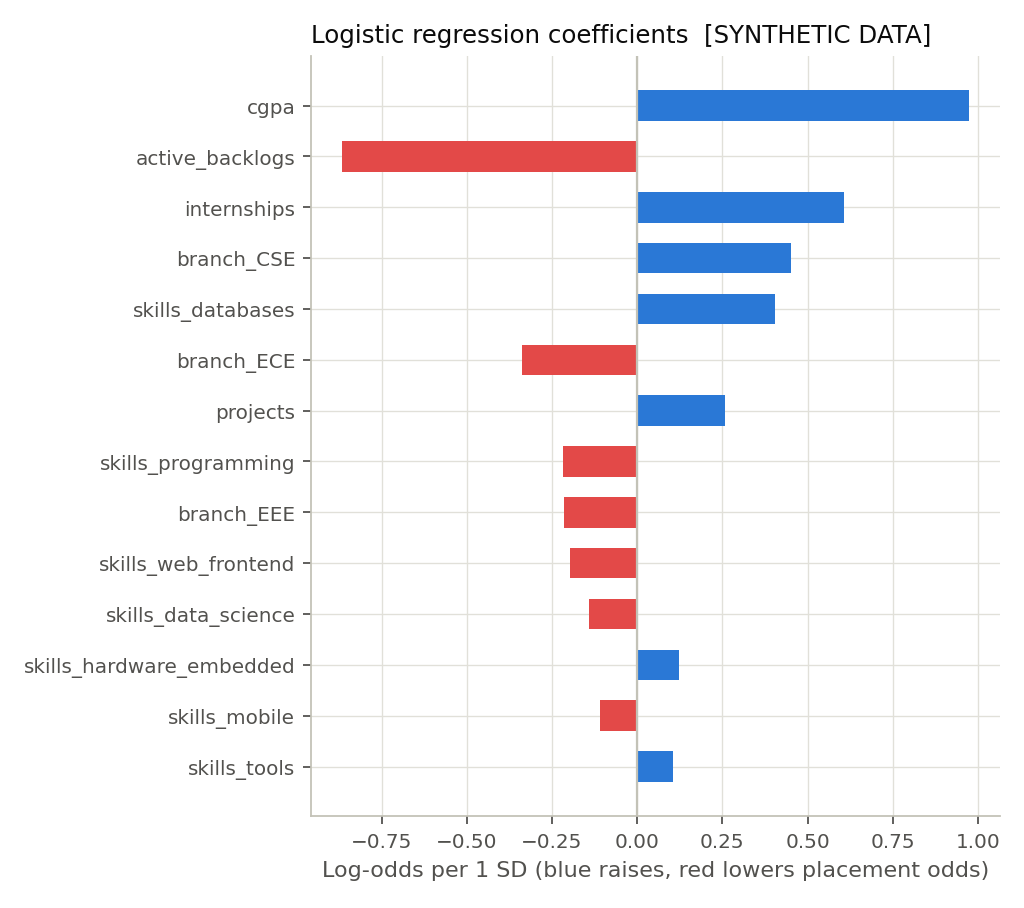

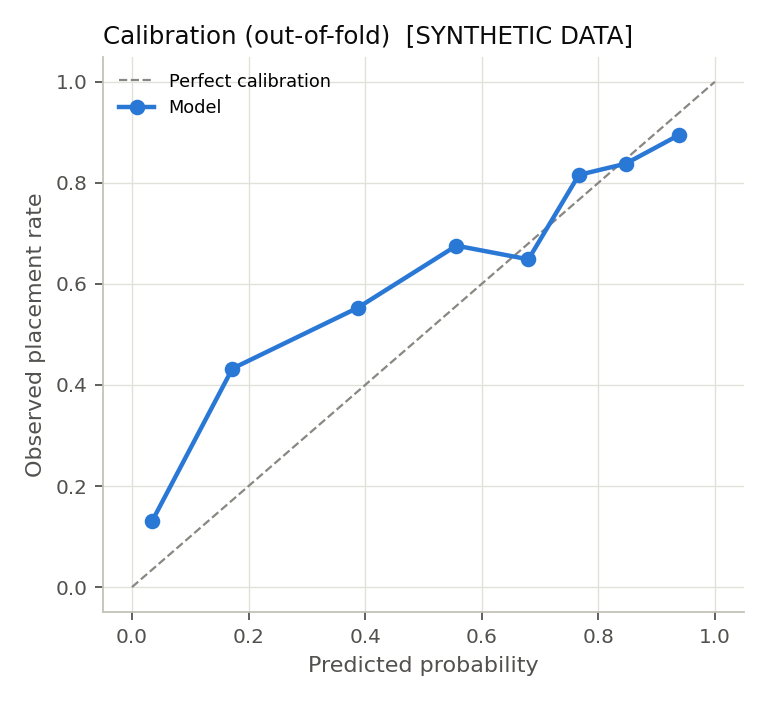

In [7]:
for f in ["roc_curves.png", "confusion_matrix.png", "coefficients.png", "calibration.png"]:
    display(Image(filename=str(ROOT / "placeiq-data/artifacts/figures" / f), width=560))